In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from rich.jupyter import display

In [46]:
path = "C:/Users/infomax/Downloads/"
file = "IRSCRS_basis_2y.csv"
filename = path + file

In [47]:
print(filename)

C:/Users/infomax/Downloads/IRSCRS_basis_2y.csv


In [55]:
basis = pd.read_csv(file, parse_dates=['Date'], index_col='Date').sort_index()

In [57]:
delta = basis["BASIS"].diff()

# Basis의 RSI
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

avg_gain = gain.ewm(alpha=1 / 14, min_periods=14, adjust=False).mean()
avg_loss = loss.ewm(alpha=1 / 14, min_periods=14, adjust=False).mean()
rs = avg_gain / avg_loss.replace(0, np.nan)

basis["RSI"] = 100 - (100 / (1 + rs))
basis.loc[(avg_loss == 0) & (avg_gain > 0), "RSI"] = 100
basis.loc[(avg_loss == 0) & (avg_gain == 0), "RSI"] = 50

# Basis의 bollinger band
window = 20
num_std = 2

basis["BB_MID"] = basis["BASIS"].rolling(window=window).mean()
std = basis["BASIS"].rolling(window=window).std()

basis["BB_UPPER"] = basis["BB_MID"] + num_std * std
basis["BB_LOWER"] = basis["BB_MID"] - num_std * std

# 원하면 %B나 밴드폭도 추가할 수 있습니다.

basis["BB_WIDTH"] = basis["BB_UPPER"] - basis["BB_LOWER"]
basis["BB_PCTB"] = (basis["BASIS"] - basis["BB_LOWER"]) / (basis["BB_UPPER"] - basis["BB_LOWER"])


In [59]:
basis.tail()

,CRS,IRS,BASIS,RSI,BB_MID,BB_UPPER,BB_LOWER,BB_WIDTH,BB_PCTB
Date,,,,,,,,,
2026-04-30,3.060,3.6300,-57.00,47.962801,-55.9500,-53.054450,-58.845550,5.791100,0.318687
2026-05-04,3.070,3.6375,-56.75,48.470221,-55.9500,-53.054450,-58.845550,5.791100,0.361857
2026-05-06,3.055,3.5900,-53.50,54.659844,-55.7750,-52.727568,-58.822432,6.094864,0.873265
2026-05-07,3.010,3.5325,-52.25,56.808729,-55.5375,-52.168622,-58.906378,6.737757,0.987922
2026-05-08,3.015,3.5475,-53.25,54.580093,-55.5375,-52.168622,-58.906378,6.737757,0.839505


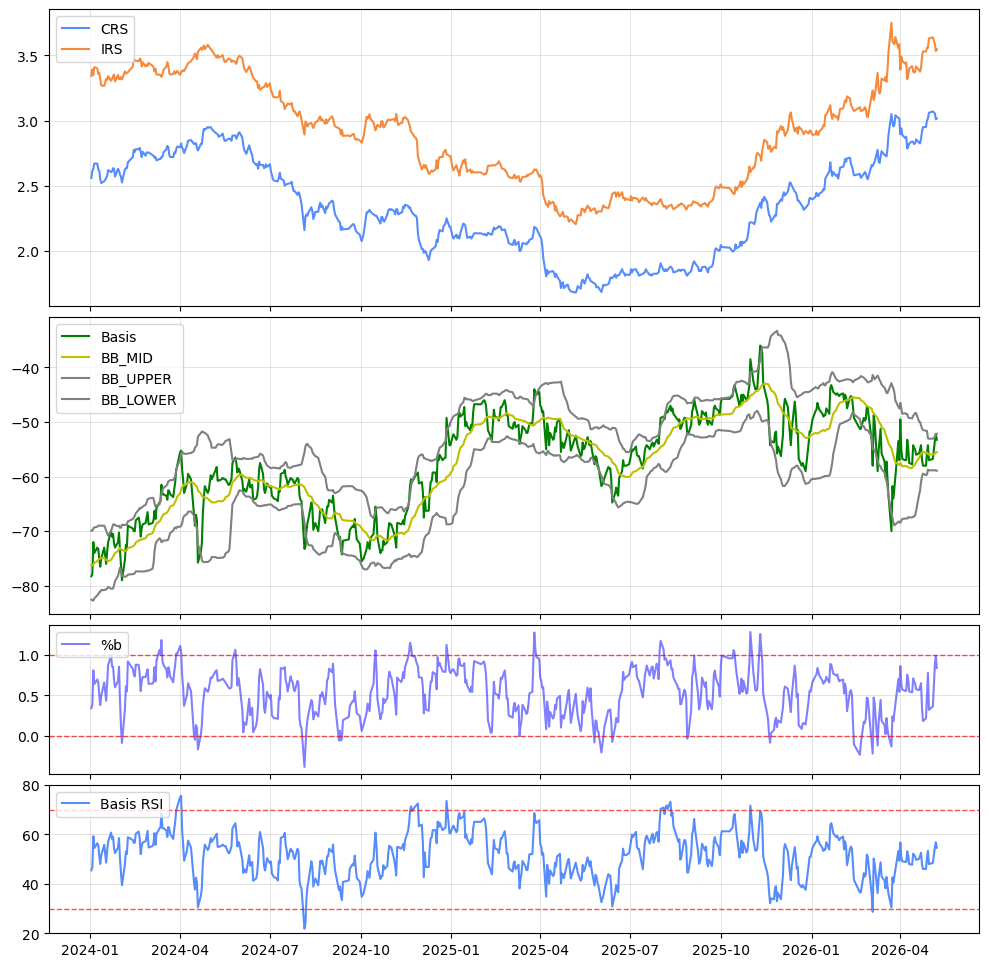

In [62]:
start = "2024-01"

fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(12, 12), sharex=True, height_ratios=(1, 1, 0.5, 0.5))

ax1.plot(basis.loc[start:basis.index[-1], ["CRS", "IRS"]], label=["CRS", "IRS"])

ax2.plot(basis.loc[start :basis.index[-1], "BASIS"], label="Basis", color='g')
ax2.plot(basis.loc[start :basis.index[-1], "BB_MID"], label="BB_MID", color='y')
ax2.plot(basis.loc[start :basis.index[-1], "BB_UPPER"], label="BB_UPPER", color='grey')
ax2.plot(basis.loc[start :basis.index[-1], "BB_LOWER"], label="BB_LOWER", color='grey')

ax3.plot(basis.loc[start :basis.index[-1], "BB_PCTB"], label="%b", color="b", alpha=0.5)
ax3.axhline(1, color='r', linestyle='--', linewidth=1, alpha=0.7)
ax3.axhline(0, color='r', linestyle='--', linewidth=1, alpha=0.7)
# ax3.axhline(0.5, color='r', linestyle='--', linewidth=1, alpha=0.7)

ax4.plot(basis.loc[start :basis.index[-1], "RSI"], label="Basis RSI")
ax4.axhline(30, color='r', linestyle='--', linewidth=1, alpha=0.7)
ax4.axhline(70, color='r', linestyle='--', linewidth=1, alpha=0.7)
ax4.set_ylim(20, 80)

fig.subplots_adjust(hspace=0.05)

ax1.grid()
ax1.legend(loc='upper left')
ax2.grid()
ax2.legend(loc='upper left')
ax3.grid()
ax3.legend(loc='upper left')
ax4.grid()
ax4.legend(loc='upper left')
plt.show()

---

### FX Swap Basis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
str_url = "https://docs.google.com/spreadsheets/d/e/2PACX-1vRfNroFE_THBtcNXvqGmIjAznHFN7d7J_oaBaUWbuGwCnpifPfAcDWDZJcgRsJ13efcmQu1LcNeXCmq/pub?output=xlsx"

In [65]:
data = pd.read_excel(str_url, sheet_name="Market_Data", index_col="DATE")

In [66]:
display(data.info())
display(data.head())

<class 'pandas.DataFrame'>
DatetimeIndex: 1593 entries, 2026-05-12 to 2019-11-25
Columns: 179 entries, KOSPI to SMBUSD_THBKRW
dtypes: datetime64[us](1), float64(174), int64(1), object(3)
memory usage: 2.2+ MB


None

,KOSPI,KOSDAQ,DJIA,SPX,CCMP,SPTSX,EUROSTOXX,FTSE,DAX,CAC,...,SMBUSD_CHFKRW,SMBUSD_GBPKRW,SMBUSD_CADKRW,SMBUSD_AUDKRW,SMBUSD_NZDKRW,SMBUSD_CNHKRW,SMBUSD_HKDKRW,SMBUSD_IDRKRW,SMBUSD_SGDKRW,SMBUSD_THBKRW
DATE,,,,,,,,,,,,,,,,,,,,,
2026-05-12,7643.15,1179.29,49760.56,7400.96,26088.20,34290.73,5808.45,10265.32,23954.93,7979.92,...,0.77795,1.36090,1.36765,0.72500,0.59665,6.79084,7.82865,17410.0,1.26885,32.275
2026-05-11,7822.24,1207.34,49704.47,7412.84,26274.13,34138.88,5895.45,10269.43,24350.28,8056.38,...,0.77785,1.35905,1.36870,0.72345,0.59495,6.80816,7.82910,17365.0,1.26825,32.275
2026-05-08,7498.00,1207.72,49609.16,7398.93,26247.08,34077.76,5911.53,10233.07,24338.63,8112.57,...,0.78085,1.35485,1.36635,0.72045,0.59355,6.79563,7.83255,17335.0,1.26945,32.315
2026-05-07,7490.05,1199.18,49596.97,7337.11,25806.20,33856.62,5972.65,10276.95,24663.61,8202.08,...,0.77855,1.35965,1.36320,0.72390,0.59575,6.81512,7.83505,17385.0,1.26790,32.225
2026-05-06,7384.56,1210.17,49910.59,7365.12,25838.94,33981.82,6027.13,10438.66,24918.69,8299.42,...,0.78160,1.35680,1.36065,0.72030,0.59020,6.81544,7.83605,17415.0,1.27445,32.450


In [67]:
data.columns.to_list()

['KOSPI',
 'KOSDAQ',
 'DJIA',
 'SPX',
 'CCMP',
 'SPTSX',
 'EUROSTOXX',
 'FTSE',
 'DAX',
 'CAC',
 'NIKKEI',
 'HIS',
 'SHS',
 'WTI',
 'BRENT',
 'XAU',
 'BTC',
 'VIX',
 'DXY',
 'KRWNDF_1M',
 'USDKRW',
 'JPYKRW',
 'EURKRW',
 'CHFKRW',
 'GBPKRW',
 'CADKRW',
 'AUDKRW',
 'NZDKRW',
 'CNYKRW',
 'HKDKRW',
 'IDRKRW',
 'SGDKRW',
 'THBKRW',
 'USDJPY',
 'EURUSD',
 'GBPUSD',
 'USDCHF',
 'USDCAD',
 'AUDUSD',
 'NZDUSD',
 'USDCNH',
 'USDCNY',
 'USDHKD',
 'USDIDR',
 'USDSGD',
 'FED_U',
 'FED_L',
 'BOC',
 'BOJ',
 'BOK',
 'RBA',
 'ECB',
 'BOE',
 'DDEP',
 'CDEP',
 'TDEP_1W',
 'TDEP_1M',
 'TDEP_3M',
 'TDEP_6M',
 'UST_1M',
 'UST_3M',
 'UST_6M',
 'UST_1Y',
 'UST_2Y',
 'UST_3Y',
 'UST_5Y',
 'UST_7Y',
 'UST_10Y',
 'UST_20Y',
 'UST_30Y',
 'KRW_CALL_ON',
 'KTB_3M',
 'KTB_6M',
 'KTB_1Y',
 'KTB_2Y',
 'KTB_3Y',
 'KTB_5Y',
 'KTB_10Y',
 'KTB_20Y',
 'KTB_30Y',
 'MSB_3M',
 'MSB_1Y',
 'MSB_2Y',
 'CD_3M',
 'CP_3M',
 'KORIBOR_1M',
 'KORIBOR_3M',
 'KORIBOR_6M',
 'KORIBOR_12M',
 'IMP_FF_ON',
 'SOFR_ON',
 'SOFR_1M',
 'SOFR_3M'

In [183]:
cols = ['KORIBOR_1M', 'KORIBOR_3M', 'KORIBOR_6M', 'KORIBOR_12M', 'SOFR_ON', 'SOFR_1M', 'SOFR_3M', 'SOFR_6M', 'SOFR_12M', 'SOFROIS_1M', 'SOFROIS_3M', 'SOFROIS_6M', 'SOFROIS_1Y', 'KOFROIS_ON', 'KOFROIS_1W', 'KOFROIS_1M', 'KOFROIS_3M', 'KOFROIS_6M', 'KOFROIS_1Y',]

df_sofr_korib = data[cols].copy()
df_sofr_korib = df_sofr_korib.sort_index()

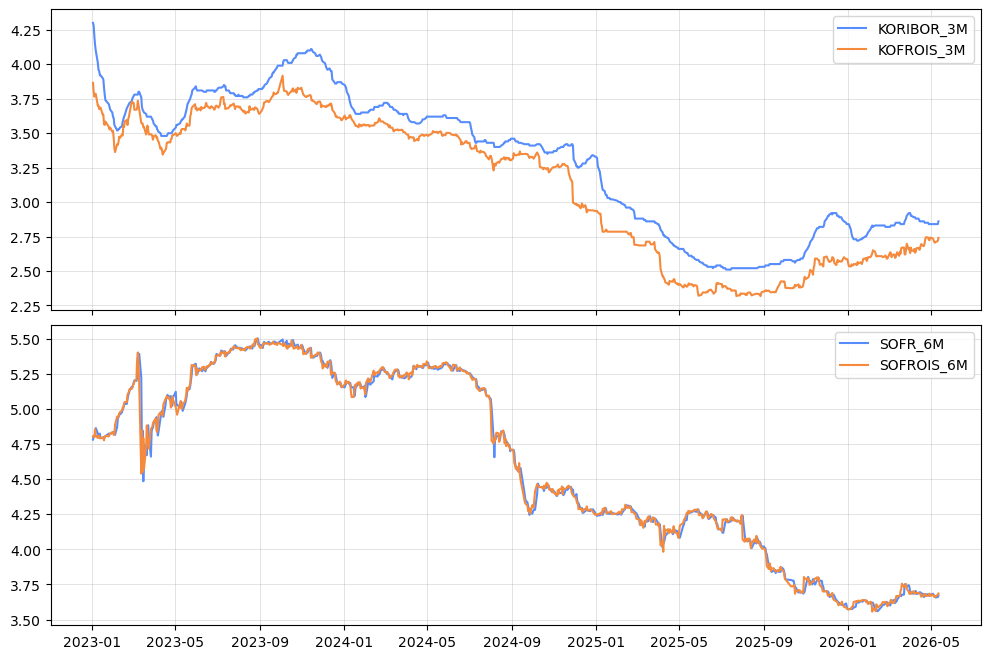

In [198]:
# 금리인상기때 스왑포인트나 일드 반응은?

# KORIBOR vs KOFROIS / SOFR vs SOFROIS

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
fig.subplots_adjust(hspace=0.05)

ax1.plot(df_sofr_korib.loc["2023":, ["KORIBOR_6M", "KOFROIS_6M"]], label=["KORIBOR_3M", "KOFROIS_3M"])
ax2.plot(df_sofr_korib.loc["2023":, ["SOFR_6M", "SOFROIS_6M"]], label=["SOFR_6M", "SOFROIS_6M"])

ax1.legend()
ax2.legend()
ax1.grid()
ax2.grid()
plt.show()

In [199]:
# Create df_fxswap
fxsw_cols = [col for col in data.columns if 'FXSW' in col]
ois_cols = [col for col in data.columns if 'OIS' in col]
cols = ["USDKRW"] + fxsw_cols + ois_cols

df_fxswap = data[cols].copy()
df_fxswap = df_fxswap.dropna().sort_index()

In [200]:
df_fxswap.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 823 entries, 2022-12-29 to 2026-05-12
Data columns (total 31 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   USDKRW      823 non-null    float64
 1   FXSW_ON     823 non-null    float64
 2   FXSW_1W     823 non-null    float64
 3   FXSW_1M     823 non-null    float64
 4   FXSW_3M     823 non-null    float64
 5   FXSW_6M     823 non-null    float64
 6   FXSW_1Y     823 non-null    float64
 7   FXSWR_ON    823 non-null    float64
 8   FXSWR_1W    823 non-null    float64
 9   FXSWR_1M    823 non-null    float64
 10  FXSWR_3M    823 non-null    float64
 11  FXSWR_6M    823 non-null    float64
 12  FXSWR_1Y    823 non-null    float64
 13  FXSWD_ON    823 non-null    float64
 14  FXSWD_1W    823 non-null    float64
 15  FXSWD_1M    823 non-null    float64
 16  FXSWD_3M    823 non-null    float64
 17  FXSWD_6M    823 non-null    float64
 18  FXSWD_1Y    823 non-null    float64
 19  SOFROIS_ON  823 non-n

In [201]:
tenors = ["ON", "1W", "1M", "3M", "6M", "1Y"]

for tenor in tenors:
    # 스왑이론가
    df_fxswap["Theo_"+tenor] = (
            df_fxswap["USDKRW"] * (df_fxswap["KOFROIS_"+tenor]/365 - df_fxswap["SOFROIS_"+tenor]/360) * df_fxswap["FXSWD_"+tenor]
    )
    # 내외금리차
    df_fxswap["RateDiff_"+tenor] = df_fxswap["KOFROIS_"+tenor] - df_fxswap["SOFROIS_"+tenor]
    # Swap Basis
    df_fxswap["SwPointBasis_"+tenor] = df_fxswap["FXSW_"+tenor] - df_fxswap["Theo_"+tenor]
    df_fxswap["SwRateBasis_"+tenor] = df_fxswap["FXSWR_"+tenor] - df_fxswap["RateDiff_"+tenor]

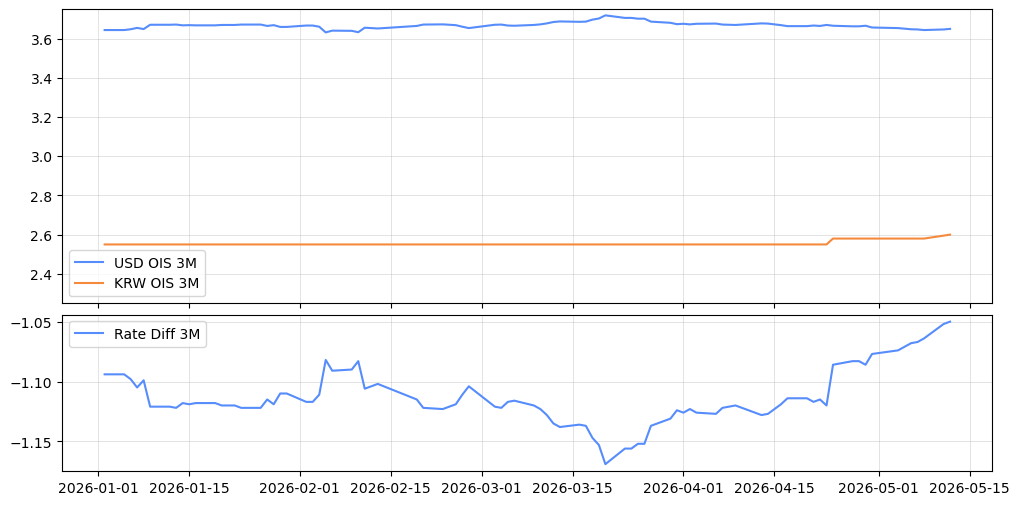

In [215]:
tenor = "3M"
start = "2026-01-01"
# resample 사용?

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), height_ratios=(1.5, 0.8), sharex=True)
fig.subplots_adjust(hspace=0.05)

ax1.plot(df_fxswap.loc[start:, "SOFROIS_"+tenor], label="USD OIS " + tenor)
ax1.plot(df_fxswap.loc[start:, "KOFROIS_"+tenor], label="KRW OIS " + tenor)
ax1.set_ylim(2.25, 3.75)

ax2.plot(df_fxswap.loc[start:, "RateDiff_"+tenor], label="Rate Diff " + tenor)
# ax2.bar(
#   df_fxswap.loc[start:].index,
#   df_fxswap.loc[start:, "RateDiff_" + tenor],
#   label="Rate Diff " + tenor,
# )

ax1.grid()
ax1.legend()
ax2.grid()
ax2.legend()

plt.show()

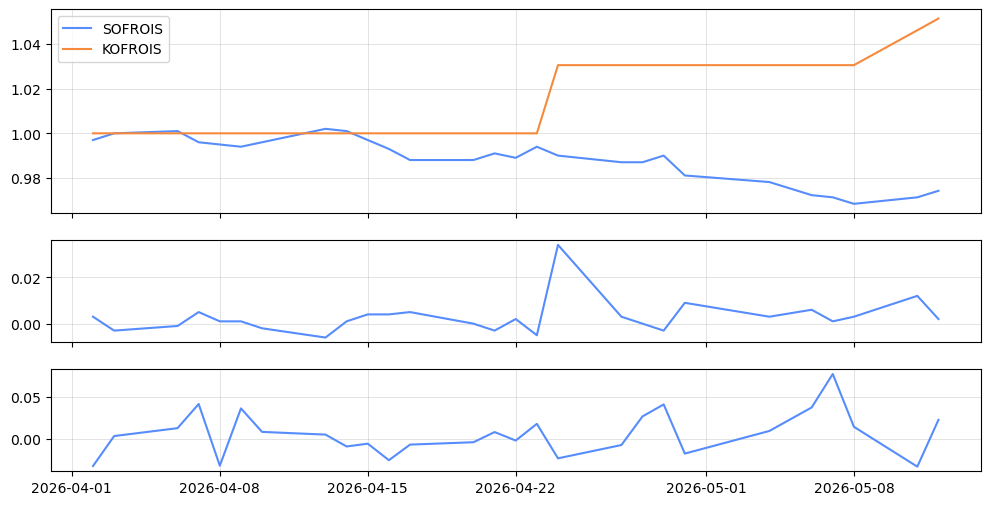

In [174]:
tenor = "3M"
start = "2026-04-01"

temp = df_fxswap.loc[start:, ["SOFROIS_"+tenor, "KOFROIS_"+tenor, "SwRateBasis_"+tenor, "RateDiff_"+tenor]].diff().dropna()
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 6), height_ratios=(2, 1, 1), sharex=True)

ax1.plot(temp[["SOFROIS_"+tenor, "KOFROIS_"+tenor]].cumsum().apply(np.exp), label=["SOFROIS", "KOFROIS"])
ax2.plot(temp["RateDiff_"+tenor])
ax3.plot(temp["SwRateBasis_"+tenor])
# ax1.legend()
ax1.grid()
ax1.legend()
ax2.grid()
ax3.grid()
plt.show()

In [82]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

TENORS = ["ON", "1W", "1M", "3M", "6M", "1Y"]
FXSWR_COLS = [f"FXSWR_{t}" for t in TENORS]
COLORS = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]

fig = make_subplots(
    rows=3, cols=2,
    subplot_titles=TENORS,
    shared_xaxes=True,
    vertical_spacing=0.08,
    horizontal_spacing=0.08,
)

positions = [(1,1),(1,2),(2,1),(2,2),(3,1),(3,2)]

for col, (row, c), tenor, color in zip(FXSWR_COLS, positions, TENORS, COLORS):
    series = df_fxswap[col].dropna()
    fig.add_trace(
        go.Scatter(
            x=series.index, y=series.values,
            name=tenor, mode="lines",
            line=dict(color=color, width=1.5),
            hovertemplate="%{x|%Y-%m-%d}<br>%{y:.4f}%<extra>" + tenor + "</extra>",
        ),
        row=row, col=c,
    )
    fig.add_hline(y=0, line_dash="dash", line_color="rgba(150,150,150,0.5)", line_width=1, row=row, col=c)

fig.update_layout(
    height=900,
    showlegend=False,
    hovermode="x unified",
    xaxis=dict(
        rangeselector=dict(
            buttons=[
                dict(count=1,  label="1M", step="month", stepmode="backward"),
                dict(count=3,  label="3M", step="month", stepmode="backward"),
                dict(count=6,  label="6M", step="month", stepmode="backward"),
                dict(count=1,  label="1Y", step="year",  stepmode="backward"),
                dict(count=2,  label="2Y", step="year",  stepmode="backward"),
                dict(step="all", label="ALL"),
            ]
        ),
        # rangeslider=dict(visible=True, thickness=0.04),
        type="date",
    ),
)
fig.update_xaxes(matches='x')
fig.update_yaxes(ticksuffix="%")
fig.show()
